# Conversion Metric Tree and Change Attribution
**Personal extension of the DSA5102 Online Shoppers project · Zheling Tang**

The course project asked *which sessions buy* (prediction, segmentation, latent structure).
This extension asks the questions a business analytics team asks every week:

1. **What is the metric tree?** How does the headline conversion rate (CVR) break into components we can monitor?
2. **Which months are actually abnormal?** A control chart that accounts for normal month-to-month variation.
3. **Why did CVR change?** An exact *mix vs rate* (shift-share) decomposition across five dimensions, with bootstrap intervals.
4. **Can we trust the metric definitions?** A data-consistency check on the intent step of the funnel.

All analysis logic lives in SQL (`sql/*.sql`, DuckDB). Python runs it, cross-checks it against an
independent NumPy implementation (`tests/`), adds the bootstrap and draws the figures.

**Data:** [UCI Online Shoppers Purchasing Intention](https://doi.org/10.24432/C5F88Q), 12,330 sessions, one year,
10 months observed (no Jan / Apr). Sessions only: no user IDs, no revenue amounts, no experiment assignment.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import attribution as A

CSV = os.environ.get('ONLINE_SHOPPERS_CSV', str(ROOT / 'data' / 'online_shoppers_intention.csv'))
con = A.connect(CSV)

BLUE, ORANGE, INK, MUTED, CRIT = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#d03b3b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': INK, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.grid': True, 'grid.color': '#ebeae6',
                     'grid.linewidth': .6, 'axes.axisbelow': True, 'font.size': 9.5,
                     'axes.titleweight': 'bold', 'axes.titlesize': 10.5,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
print('sessions, purchases =', con.execute('SELECT count(*), sum(purchase) FROM sessions').fetchone())

sessions, purchases = (12330, 1908)


## 1. Metric tree

```
Purchases = Sessions × CVR
CVR       = s_hi × CVR_hi + (1 − s_hi) × CVR_lo
            s_hi   : share of sessions that reached a page with PageValues > 0
                     (Google Analytics "page value": pages that preceded a transaction)
            CVR_hi : conversion of those sessions        CVR_lo : conversion of the rest
Guardrails: bounce-heavy share (BounceRates ≥ 0.2), new-visitor share
```

`s_hi` is a funnel step (did the session get close to checkout?), `CVR_hi` is closing efficiency.
The identity holds exactly every month (`kpi_identity_check`, tested).

,month,sessions,purchases,cvr,s_hi,cvr_hi,cvr_lo,bounce_heavy_share,new_visitor_share
0,Feb,184,3,0.0163,0.0326,0.5000,0.0000,0.1848,0.0054
1,Mar,1907,192,0.1007,0.1542,0.6531,0.0000,0.0692,0.1217
2,May,3364,365,0.1085,0.2209,0.4913,0.0000,0.0633,0.0948
3,June,288,29,0.1007,0.1875,0.4259,0.0256,0.0903,0.1042
4,Jul,432,66,0.1528,0.2384,0.4563,0.0578,0.0486,0.1250
5,Aug,433,76,0.1755,0.2610,0.5221,0.0531,0.0277,0.1663
6,Sep,448,86,0.1920,0.2790,0.4640,0.0867,0.0134,0.2411
7,Oct,549,115,0.2095,0.3133,0.5814,0.0398,0.0128,0.2259
8,Nov,2998,760,0.2535,0.2605,0.6594,0.1105,0.0497,0.1398
9,Dec,1727,216,0.1251,0.1963,0.5192,0.0288,0.0579,0.1940


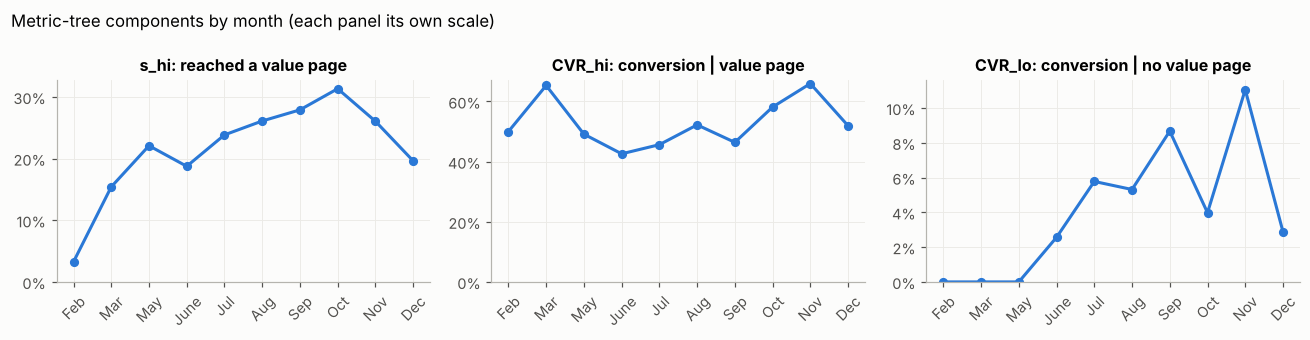

In [2]:
kpi = con.execute('SELECT * FROM kpi_month').df()
assert con.execute('SELECT max(abs(identity_gap)) FROM kpi_identity_check').fetchone()[0] < 1e-12
display(kpi[['month_raw','sessions','purchases','cvr','s_hi','cvr_hi','cvr_lo',
             'bounce_heavy_share','new_visitor_share']].rename(columns={'month_raw': 'month'}))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.1), sharex=True)
for ax, col, title in zip(axes, ['s_hi', 'cvr_hi', 'cvr_lo'],
        ['s_hi: reached a value page', 'CVR_hi: conversion | value page', 'CVR_lo: conversion | no value page']):
    ax.plot(kpi.month_raw, kpi[col], color=BLUE, lw=2, marker='o', ms=5)
    ax.set_title(title); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
    ax.set_ylim(0, None); ax.tick_params(axis='x', labelrotation=45)
fig.suptitle('Metric-tree components by month (each panel its own scale)', x=.01, ha='left', fontsize=11)
fig.tight_layout(); plt.show()

## 2. Which months are abnormal? Laney p′-chart

A plain p-chart with thousands of sessions per month flags almost everything, because real
month-to-month variation is far larger than binomial noise. Laney's p′ chart widens the binomial
limits by σ_z, the spread of monthly z-scores (moving-range estimate), so a flag means
"unusual even given ordinary seasonal swings" (`sql/04_monitoring.sql`).

,month,n,cvr,z,lcl,ucl,flag
0,Feb,184,0.0163,-5.1924,-0.1837,0.4932,in_control
1,Mar,1907,0.1007,-6.5279,0.0496,0.2599,in_control
2,May,3364,0.1085,-7.4160,0.0756,0.2339,in_control
3,June,288,0.1007,-2.5362,-0.1158,0.4252,in_control
4,Jul,432,0.1528,-0.1130,-0.0661,0.3756,in_control
5,Aug,433,0.1755,1.1953,-0.0659,0.3753,in_control
6,Sep,448,0.1920,2.1783,-0.0621,0.3716,in_control
7,Oct,549,0.2095,3.5456,-0.0412,0.3507,in_control
8,Nov,2998,0.2535,14.9515,0.0709,0.2386,above
9,Dec,1727,0.1251,-3.4095,0.0443,0.2652,in_control


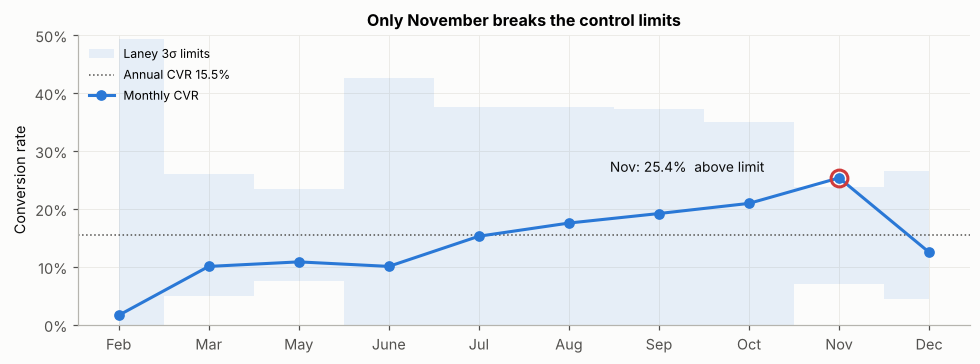

**Reading.** σ_z = 4.23: monthly variation is ~4× binomial noise.
November (25.4%) is the only month above its limit. December's
12.5% is inside the limits, so the Nov→Dec "drop" is mostly
a return from an unusual November, not a December failure. The useful questions are therefore
(a) *what made November high* and (b) *what changed from November to December*.

In [3]:
ctl = con.execute('SELECT * FROM cvr_control').df()
display(ctl[['month_raw','n','cvr','z','lcl','ucl','flag']].rename(columns={'month_raw': 'month'}))
x = np.arange(len(ctl))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.fill_between(x, ctl.lcl.clip(lower=0), ctl.ucl, step='mid', color=BLUE, alpha=.10, lw=0,
                label='Laney 3σ limits')
ax.axhline(ctl.pbar.iloc[0], color=MUTED, lw=1, ls=':', label=f'Annual CVR {ctl.pbar.iloc[0]:.1%}')
ax.plot(x, ctl.cvr, color=BLUE, lw=2, marker='o', ms=6, label='Monthly CVR')
for i, r in ctl.iterrows():
    if r.flag != 'in_control':
        ax.plot(i, r.cvr, 'o', ms=11, mfc='none', mec=CRIT, mew=2)
        ax.annotate(f'{r.month_raw}: {r.cvr:.1%}  above limit', (i, r.cvr), xytext=(-150, 4),
                    textcoords='offset points', color=INK, fontsize=9)
ax.set_xticks(x, ctl.month_raw); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set(ylim=(0, .5), ylabel='Conversion rate', title='Only November breaks the control limits')
ax.legend(loc='upper left', fontsize=8, frameon=False); fig.tight_layout(); plt.show()
display(Markdown(f"""**Reading.** σ_z = {ctl.sigma_z.iloc[0]:.2f}: monthly variation is ~4× binomial noise.
November ({ctl.set_index('month_raw').loc['Nov','cvr']:.1%}) is the only month above its limit. December's
{ctl.set_index('month_raw').loc['Dec','cvr']:.1%} is inside the limits, so the Nov→Dec "drop" is mostly
a return from an unusual November, not a December failure. The useful questions are therefore
(a) *what made November high* and (b) *what changed from November to December*."""))

## 3. Why did CVR change? Mix vs rate attribution

For one dimension with segments *i*, CVR = Σ wᵢ rᵢ (wᵢ = session share, rᵢ = segment CVR). Between
periods 0 and 1 (`sql/03_shift_share.sql`):

$$\Delta\text{CVR}=\underbrace{\sum_i \Delta w_i\,(\bar r_i-\overline{\text{CVR}})}_{\text{mix: traffic moved between segments}}
+\underbrace{\sum_i \Delta r_i\,\bar w_i}_{\text{rate: segments converted differently}}$$

Bars are two-period averages. The split is exact (no residual). Centring the mix term at the average
CVR makes each segment's mix contribution readable: gaining share helps only if the segment converts
above average. Uncertainty: 2,000 bootstrap resamples of sessions within each month (95% percentile
intervals). Five dimensions are decomposed separately; each answers "how much would CVR have moved
from re-weighting this dimension alone?"

| Comparison | Why |
|---|---|
| Jul–Oct (pooled) → Nov | What made the flagged month high? Pooled baseline avoids Oct's small sample |
| Nov → Dec | What changed in the largest month-over-month fall? |

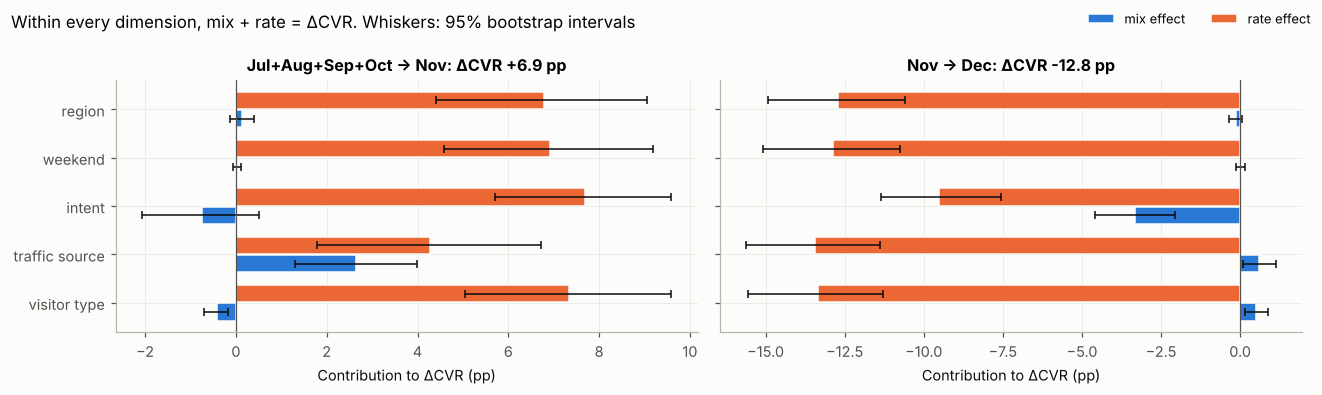

**Jul+Aug+Sep+Oct → Nov**

,mix_effect,mix_lo,mix_hi,rate_effect,rate_lo,rate_hi,mix_share_of_change
dimension,,,,,,,
traffic_source,0.0265,0.0131,0.0400,0.0428,0.0179,0.0673,0.3820
intent,-0.0075,-0.0207,0.0051,0.0768,0.0570,0.0959,-0.1088
visitor_type,-0.0041,-0.0070,-0.0017,0.0734,0.0504,0.0958,-0.0590
region,0.0013,-0.0014,0.0039,0.0679,0.0440,0.0905,0.0195
weekend,0.0002,-0.0006,0.0012,0.0691,0.0457,0.0918,0.0026


**Nov → Dec**

,mix_effect,mix_lo,mix_hi,rate_effect,rate_lo,rate_hi,mix_share_of_change
dimension,,,,,,,
intent,-0.0334,-0.0459,-0.0206,-0.0951,-0.1136,-0.0755,0.2598
traffic_source,0.0060,0.0008,0.0112,-0.1345,-0.1560,-0.1138,-0.0470
visitor_type,0.0051,0.0014,0.0089,-0.1336,-0.1557,-0.1127,-0.0399
region,-0.0012,-0.0035,0.0007,-0.1272,-0.1493,-0.1059,0.0094
weekend,0.0002,-0.0012,0.0016,-0.1286,-0.1509,-0.1075,-0.0015


In [4]:
COMPARISONS = [(['Jul', 'Aug', 'Sep', 'Oct'], 'Nov'), ('Nov', 'Dec')]
results = {}
for base, comp in COMPARISONS:
    point = A.summary_sql(con, base, comp).set_index('dimension')
    boot = A.bootstrap_summary(con, base, comp, reps=2000, seed=42).set_index('dimension')
    results[(A.label(base), comp)] = point.join(boot)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
order = A.DIMENSIONS
for ax, ((b, c), res) in zip(axes, results.items()):
    res = res.loc[order]
    y = np.arange(len(order))
    for off, kind, color in [(-.19, 'mix', BLUE), (.19, 'rate', ORANGE)]:
        val = res[f'{kind}_effect'] * 100
        err = np.vstack([val - res[f'{kind}_lo'] * 100, res[f'{kind}_hi'] * 100 - val])
        ax.barh(y + off, val, height=.36, color=color, label=f'{kind} effect',
                edgecolor='#fcfcfb', linewidth=1)
        ax.errorbar(val, y + off, xerr=err, fmt='none', ecolor=INK, elinewidth=1, capsize=2.5)
    ax.axvline(0, color=MUTED, lw=.8)
    delta = res.delta_cvr.iloc[0] * 100
    ax.set_title(f'{b} → {c}: ΔCVR {delta:+.1f} pp'); ax.set_xlabel('Contribution to ΔCVR (pp)')
    ax.set_yticks(y, [d.replace('_', ' ') for d in order]); ax.invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=8.5,
           loc='upper right', ncol=2)
fig.suptitle('Within every dimension, mix + rate = ΔCVR. Whiskers: 95% bootstrap intervals',
             x=.01, ha='left', fontsize=11)
fig.tight_layout(); plt.show()
for key, res in results.items():
    display(Markdown(f'**{key[0]} → {key[1]}**'))
    display(res[['mix_effect','mix_lo','mix_hi','rate_effect','rate_lo','rate_hi','mix_share_of_change']])

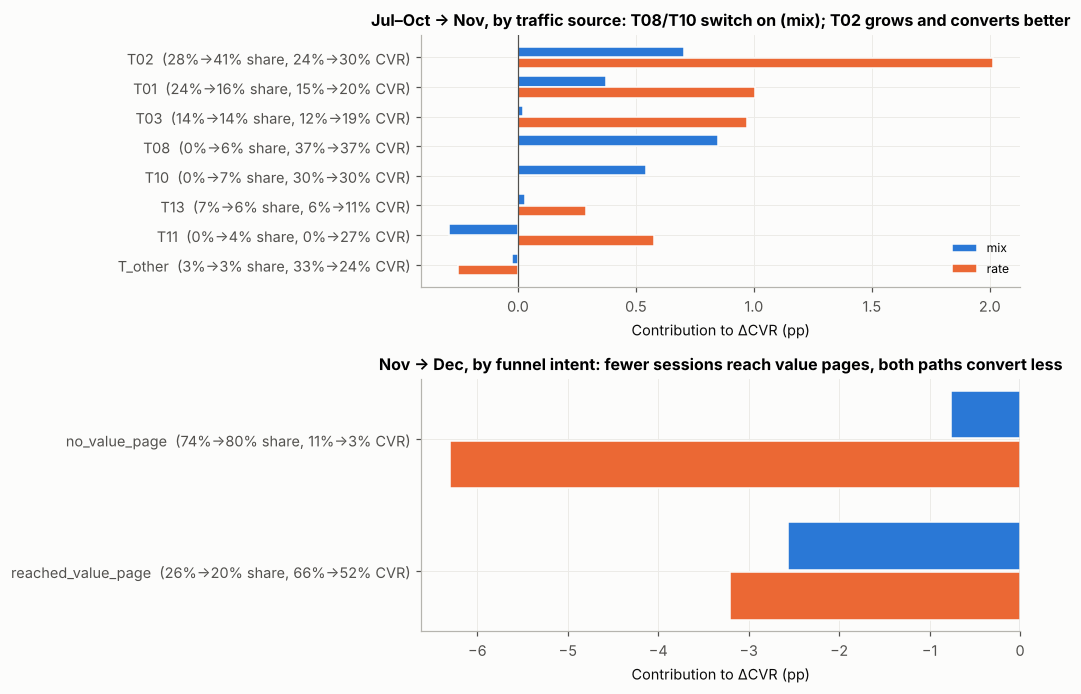

In [5]:
def segment_plot(ax, base, comp, dim, title):
    seg = A.shift_share_sql(con, dim, base, comp)
    seg = seg[seg.n0 + seg.n1 >= 30].head(8)
    y = np.arange(len(seg))
    ax.barh(y - .19, seg.mix_effect * 100, height=.36, color=BLUE, label='mix', edgecolor='#fcfcfb')
    ax.barh(y + .19, seg.rate_effect * 100, height=.36, color=ORANGE, label='rate', edgecolor='#fcfcfb')
    ax.set_yticks(y, [f'{s}  ({w0:.0%}→{w1:.0%} share, {r0:.0%}→{r1:.0%} CVR)'
                      for s, w0, w1, r0, r1 in seg[['segment','w0','w1','r0','r1']].itertuples(index=False)])
    ax.invert_yaxis(); ax.axvline(0, color=MUTED, lw=.8)
    ax.set(title=title, xlabel='Contribution to ΔCVR (pp)')
    return seg

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.4))
s1 = segment_plot(axes[0], ['Jul','Aug','Sep','Oct'], 'Nov', 'traffic_source',
                  'Jul–Oct → Nov, by traffic source: T08/T10 switch on (mix); T02 grows and converts better')
s2 = segment_plot(axes[1], 'Nov', 'Dec', 'intent',
                  'Nov → Dec, by funnel intent: fewer sessions reach value pages, both paths convert less')
axes[0].legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout(); plt.show()

In [6]:
for (b, c) in [(['Jul','Aug','Sep','Oct'], 'Nov'), ('Nov', 'Dec')]:
    display(Markdown('```\n' + A.driver_summary(con, b, c) + '\n```'))

```
CVR Jul+Aug+Sep+Oct 18.42% -> Nov 25.35% (+6.93 pp).
Largest mix effect: traffic_source (+2.65 pp, 38% of the change); the rest is within-segment rate change.
- visitor_type: Returning_Visitor +6.30 pp (share 81%->85%, CVR 17.0%->24.6%); New_Visitor +0.69 pp (share 19%->14%, CVR 24.6%->30.5%); Other -0.06 pp (share 0%->1%, CVR 13.6%->13.6%)
- traffic_source: T02 +2.72 pp (share 28%->41%, CVR 24.3%->30.1%); T01 +1.37 pp (share 24%->16%, CVR 14.9%->20.0%); T03 +0.99 pp (share 14%->14%, CVR 11.6%->18.6%)
- intent: no_value_page +3.60 pp (share 72%->74%, CVR 5.9%->11.1%); reached_value_page +3.33 pp (share 28%->26%, CVR 51.5%->65.9%)
- weekend: weekday +4.82 pp (share 76%->74%, CVR 18.5%->24.9%); weekend +2.11 pp (share 24%->26%, CVR 18.2%->26.5%)
- region: R1 +3.24 pp (share 36%->43%, CVR 19.2%->27.2%); R3 +1.94 pp (share 20%->19%, CVR 16.1%->26.1%); R2 +0.64 pp (share 9%->8%, CVR 21.6%->29.8%)
```

```
CVR Nov 25.35% -> Dec 12.51% (-12.84 pp).
Largest mix effect: intent (-3.34 pp, 26% of the change); the rest is within-segment rate change.
- visitor_type: Returning_Visitor -12.00 pp (share 85%->77%, CVR 24.6%->9.6%); New_Visitor -0.95 pp (share 14%->19%, CVR 30.5%->22.4%); Other +0.11 pp (share 1%->4%, CVR 13.6%->21.0%)
- traffic_source: T02 -6.21 pp (share 41%->45%, CVR 30.1%->15.5%); T01 -2.45 pp (share 16%->22%, CVR 20.0%->8.6%); T03 -1.32 pp (share 14%->9%, CVR 18.6%->4.3%)
- intent: no_value_page -7.07 pp (share 74%->80%, CVR 11.1%->2.9%); reached_value_page -5.77 pp (share 26%->20%, CVR 65.9%->51.9%)
- weekend: weekday -9.08 pp (share 74%->79%, CVR 24.9%->13.0%); weekend -3.76 pp (share 26%->21%, CVR 26.5%->10.7%)
- region: R1 -6.00 pp (share 43%->36%, CVR 27.2%->12.1%); R3 -3.00 pp (share 19%->20%, CVR 26.1%->10.8%); R2 -1.48 pp (share 8%->8%, CVR 29.8%->11.3%)
```

**Findings.**

* **What made November high (+6.9 pp vs Jul–Oct).** Traffic mix explains **+2.7 pp (~38%)**,
  95% CI about +1.3 to +4.0 pp. About half of that (+1.4 pp) comes from two sources, T08 and T10, that
  are **active only in Mar, Nov and Dec**. They were absent in Jul–Oct, made up 12.5% of November
  sessions and converted at 30–37%, which looks like campaign channels switching on. Source T02 also grew
  from 28% to 41% of sessions (+0.7 pp mix) and converted better (+2.0 pp rate). The remaining ~62% is a
  within-segment lift seen in nearly every visitor type, region, weekday/weekend and both funnel paths,
  which looks like a site-wide seasonal or promotional effect rather than one channel.
* **What changed Nov → Dec (−12.8 pp).** Traffic mix did *not* cause it: its contribution is slightly
  positive. The largest mix effect is in the funnel. Fewer sessions reached a value page (26% → 20%),
  worth **−3.3 pp (~26%)**, CI about −4.6 to −2.1 pp. The rest is lower conversion on both paths
  (CVR_hi 66% → 52%, CVR_lo 11% → 3%), with every major source and region falling.
* **Operational reading.** For November's spike, check the campaign calendar: what ran on T08/T10 and
  what drove the site-wide lift. December needs funnel diagnosis (product → value-page step), not a
  channel investigation.

**What this does not show.** These are accounting decompositions of observational data, not causal
effects. "Traffic mix explains 2.7 pp" means "re-weighting segments to November's shares moves CVR by
2.7 pp at the average segment rates", not "buying more T08/T10 traffic would raise CVR by that much";
marginal users from a scaled-up channel may convert differently. A segment absent in one period has
no rate there, so its whole contribution is booked as mix (convention documented in the SQL).
Decompositions also depend on the segmentation chosen, and dimensions overlap (they are not additive
across dimensions). The intent step is itself
a behavioural outcome, so its "mix" is a funnel shift, not an external traffic shift.

## 4. Can we trust the funnel definition? A consistency check

If `PageValues > 0` marks "reached a page preceding a transaction", purchases with no value page
should be rare *and stable over time*. They are not:

,month,purchases,purchases_without_value_page,share_of_purchases
0,Feb,3,0,0.0000
1,Mar,192,0,0.0000
2,May,365,0,0.0000
3,June,29,6,0.2069
4,Jul,66,19,0.2879
5,Aug,76,17,0.2237
6,Sep,86,28,0.3256
7,Oct,115,15,0.1304
8,Nov,760,245,0.3224
9,Dec,216,40,0.1852


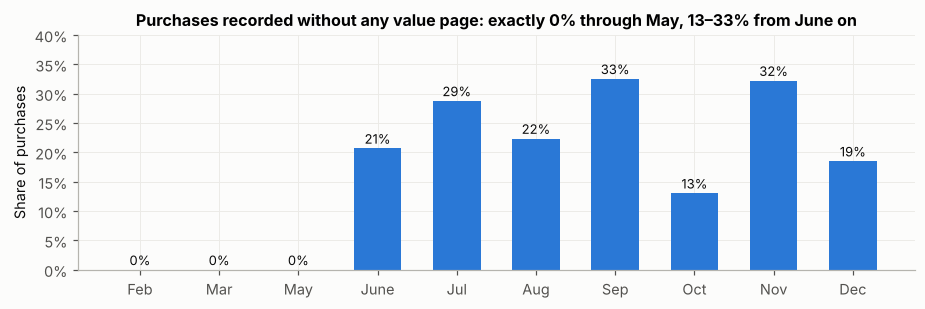

In [7]:
dq = kpi[['month_raw', 'purchases', 'purchases_without_value_page']].copy()
dq['share_of_purchases'] = dq.purchases_without_value_page / dq.purchases
display(dq.rename(columns={'month_raw': 'month'}))
fig, ax = plt.subplots(figsize=(8.5, 2.9))
ax.bar(dq.month_raw, dq.share_of_purchases, color=BLUE, width=.6)
for i, r in dq.iterrows():
    ax.text(i, r.share_of_purchases + .008, f'{r.share_of_purchases:.0%}', ha='center', fontsize=8.5, color=INK)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set(ylabel='Share of purchases', ylim=(0, .4),
       title='Purchases recorded without any value page: exactly 0% through May, 13–33% from June on')
fig.tight_layout(); plt.show()

**Reading.** In Feb, Mar and May, *every* purchase has PageValues > 0. From June on, 13–33% do not.
A step change like this is more consistent with a change in tracking or attribution windows than with
user behaviour. Consequences:

* `s_hi`, `CVR_hi` and `CVR_lo` are **comparable within Jun–Dec** (both attribution comparisons above
  stay inside that regime) but should not be trended across May → June without a caveat.
* In a production setting this would be raised with the tracking owner before anyone builds a target on `s_hi`.
* It also adds to the leakage concern for PageValues in the course project's prediction task: the
  feature's meaning may not be fixed over time.

## 5. Limitations and next steps

| Limitation | Implication |
|---|---|
| No user IDs or dates within a month | No retention, cohort or weekly monitoring; months are the smallest period |
| No revenue amount | Purchases stand in for GMV; AOV cannot be decomposed |
| Anonymised traffic / region codes | Findings name codes (T02, T08) and cannot be tied to real channels |
| Observational data | Attribution ≠ causal effect; an experiment would be needed to size interventions |
| One year, 10 months | The control limits rest on 10 points and are indicative only |

**Next:** (B) an experiment-analysis module on a randomised e-commerce dataset (SRM, CUPED, delta
method, heterogeneous effects), and (C) an LLM layer that turns `driver_summary()` output into a
written explanation with automatic number checks.